# ROMY tilt correction

Compare horizontal translation components ($a_N$, $a_E$) before and after tilt correction for a single ROMY event.

With `time_cuts`, the stream is split into continuous intervals between gaps (N gaps → N+1 segments). Each segment is `correct_tilt()`-ed separately and merged back so integration never runs through zero-filled windows.

Tilt coupling: $a_N \leftarrow a_N + g\,\dot\omega_E$ and $a_E \leftarrow a_E - g\,\dot\omega_N$ (with $g = 9.81$ m s$^{-2}$).

In [64]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from obspy import UTCDateTime
from sixdegrees.sixdegrees import sixdegrees

In [65]:
# Publication-style defaults
plt.rcParams.update({
    "font.size": 11,
    "font.family": "serif",
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "ytick.minor.visible": True,
    "xtick.minor.visible": True,
    "legend.frameon": False,
    "figure.dpi": 200,
})

In [66]:
# Event to analyse (change as needed)
date = "20260107" # "20260107" # "20230908"

save_figure = True
output_dir = "./output/figures/tilt_correction"

In [67]:
config_path = f"./events/event_{date}/config_romy_{date}.yml"
if not os.path.exists(config_path):
    raise FileNotFoundError(f"Config not found: {config_path}")

config = sixdegrees.load_from_yaml(config_path)
sd = sixdegrees(conf=config)

try:
    ev = sd.get_event_info(
        origin_time=config["origin_time"],
        base_catalog="USGS",
        magnitude=config.get("magnitude"),
    )
except Exception:
    ev = {
        "origin_time": UTCDateTime(config["origin_time"]),
        "magnitude": config.get("magnitude"),
        "backazimuth": np.nan,
        "distance_km": np.nan,
    }

sd.load_data(config["tbeg"], config["tend"], resample_rate=5)
sd.trim_stream(set_common=True, set_interpolate=True)
sd.filter_data(fmin=config["fmin"], fmax=config["fmax"], output=False)

if "pol_dict" in config:
    sd.polarity_stream(pol_dict=config["pol_dict"], raw=True)
else:
    sd.polarity_stream(pol_dict={"HZ": -1, "JZ": 1}, raw=True)

if "time_cuts" in config:
    for key, entries in config["time_cuts"].items():
        if not entries:
            continue
        if len(entries) == 2 and isinstance(entries[0], str):
            entries = [entries]
        for entry in entries:
            sd.replace_values_in_window(
                tbeg=entry[0], tend=entry[1], value=0, channel_list=[key]
            )

st_before = sd.st.copy()

def _merge_windows(windows):
    if not windows:
        return []
    unique = sorted(
        {(float(a), float(b)): (a, b) for a, b in windows}.values(),
        key=lambda w: w[0],
    )
    merged = [unique[0]]
    for tbeg, tend in unique[1:]:
        if tbeg <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(merged[-1][1], tend))
        else:
            merged.append((tbeg, tend))
    return merged

def _cut_mask(trace, windows):
    mask = np.zeros(len(trace.data), dtype=bool)
    if not windows:
        return mask
    t0, dt = trace.stats.starttime, trace.stats.delta
    for tbeg, tend in windows:
        i0 = int(np.ceil((tbeg - t0) / dt))
        i1 = int(np.floor((tend - t0) / dt))
        mask[max(0, i0):min(len(mask), i1 + 1)] = True
    return mask

def _segments_outside(stream, windows):
    if not windows:
        tr = stream[0]
        return [(tr.stats.starttime, tr.stats.endtime)]
    dt = stream[0].stats.delta
    t_start, t_end = stream[0].stats.starttime, stream[0].stats.endtime
    segments, cursor = [], t_start
    for cut_beg, cut_end in windows:
        if cut_beg > cursor:
            segments.append((cursor, cut_beg - dt))
        cursor = max(cursor, cut_end + dt)
    if cursor <= t_end:
        segments.append((cursor, t_end))
    return segments

def _paste_segment(full_st, seg_before, seg_after):
    """Merge one segment; remove spurious per-segment DC from ∫ω reset."""
    dt, t0 = full_st[0].stats.delta, full_st[0].stats.starttime
    for channel in ("HN", "HE"):
        full_tr = full_st.select(channel=f"*{channel}")[0]
        tr_b = seg_before.select(channel=f"*{channel}")[0]
        tr_a = seg_after.select(channel=f"*{channel}")[0]
        delta = tr_b.data - tr_a.data
        delta = delta - np.mean(delta)
        corrected = tr_b.data - delta
        i0 = int(round((tr_a.stats.starttime - t0) / dt))
        n = len(corrected)
        i0 = max(0, min(i0, len(full_tr.data) - n))
        full_tr.data[i0:i0 + n] = corrected

cut_windows = []
if "time_cuts" in config:
    for entries in config["time_cuts"].values():
        if not entries:
            continue
        if len(entries) == 2 and isinstance(entries[0], str):
            entries = [entries]
        for entry in entries:
            cut_windows.append((UTCDateTime(entry[0]), UTCDateTime(entry[1])))
    cut_windows = _merge_windows(cut_windows)

if cut_windows:
    full_st = sd.st.copy()
    segments = _segments_outside(full_st, cut_windows)
    print(
        f"Tilt correction: {len(segments)} segment(s) outside "
        f"{len(cut_windows)} cut window(s)"
    )
    for seg_start, seg_end in segments:
        seg_st = full_st.slice(starttime=seg_start, endtime=seg_end).copy()
        if len(seg_st) == 0 or len(seg_st[0].data) < 2:
            continue
        seg_before = seg_st.copy()
        sd.st = seg_st
        sd.correct_tilt(data_type="acceleration")
        _paste_segment(full_st, seg_before, seg_st)
    sd.st = full_st
else:
    sd.correct_tilt(data_type="acceleration")

st_after = sd.st.copy()

print(f"Loaded event {date}")
print(f"Filter band: {config['fmin']:.3f}–{config['fmax']:.2f} Hz")
print(f"Magnitude: {config.get('magnitude', 'n/a')}")

Found event:
Origin time: 2026-01-07T03:02:53.890000Z
Magnitude: 6.4 mww
Location: 7.245°N, 126.895°E
Depth: 22.0 km
Epicentral Distance: 11249.87 km
Epicentral Distance: 101.2°
Backazimuth: 65.58°
-> fetching XX.ROMY..BHZ data from mseed file
-> fetching XX.ROMY..BHN data from mseed file
-> fetching XX.ROMY..BHE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BHZ | 2026-01-07T03:11:58.990000Z - 2026-01-07T04:30:00.990000Z | 20.0 Hz, 93641 samples
XX.ROMY..BHN | 2026-01-07T03:11:58.989999Z - 2026-01-07T04:30:00.989999Z | 20.0 Hz, 93641 samples
XX.ROMY..BHE | 2026-01-07T03:11:58.989999Z - 2026-01-07T04:30:00.989999Z | 20.0 Hz, 93641 samples
-> fetching XX.ROMY..BJZ data from mseed file
-> fetching XX.ROMY..BJN data from mseed file
-> fetching XX.ROMY..BJE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BJZ | 2026-01-07T03:11:58.991800Z - 2026-01-07T04:30:00.991800Z | 20.0 Hz, 93641 samples
XX.ROMY..BJN | 2026-01-07T03:11:59.003400Z - 2026-01-07T04:30:01.003400Z | 20.0 Hz, 93641 

In [68]:
cut_mask = None
hn_ref = st_after.select(channel="*HN")
if hn_ref and cut_windows:
    cut_mask = _cut_mask(hn_ref[0], cut_windows)

def trace_stats(before_tr, after_tr, cut_mask=None, scale=1e6):
    """RMS (µm/s²) and variance reduction (%), excluding cut windows."""
    b, a = before_tr.data, after_tr.data
    if cut_mask is not None and len(cut_mask) == len(b):
        valid = ~cut_mask
        if np.any(valid):
            b, a = b[valid], a[valid]
    rms_b = np.sqrt(np.mean(b ** 2)) * scale
    rms_a = np.sqrt(np.mean(a ** 2)) * scale
    var_b, var_a = np.var(b), np.var(a)
    var_red = 100.0 * (var_b - var_a) / var_b if var_b > 0 else np.nan
    return {
        "rms_before": rms_b,
        "rms_after": rms_a,
        "var_reduction_pct": var_red,
    }


def relative_time_minutes(trace, ref_time):
    return (trace.times(reftime=ref_time)) / 60.0


components = [
    ("HN", r"$a_N$"),
    ("HE", r"$a_E$"),
]

ref_time = UTCDateTime(config["tbeg"])
unit_label = r"$\mu$m/s$^{{2}}$"
scale = 1e6

stats = {}
for ch, label in components:
    tr_b = st_before.select(channel=f"*{ch}")[0]
    tr_a = st_after.select(channel=f"*{ch}")[0]
    stats[ch] = trace_stats(tr_b, tr_a, cut_mask=cut_mask, scale=scale)
    s = stats[ch]
    print(
        f"{label}: RMS before = {s['rms_before']:.3f}, after = {s['rms_after']:.3f} "
        f"µm/s² | variance reduction = {s['var_reduction_pct']:.2f}%"
    )

$a_N$: RMS before = 0.202, after = 0.202 µm/s² | tilt artefact RMS = 0.0016 µm/s² (0.79% of signal)
$a_E$: RMS before = 0.246, after = 0.247 µm/s² | tilt artefact RMS = 0.0018 µm/s² (0.71% of signal)


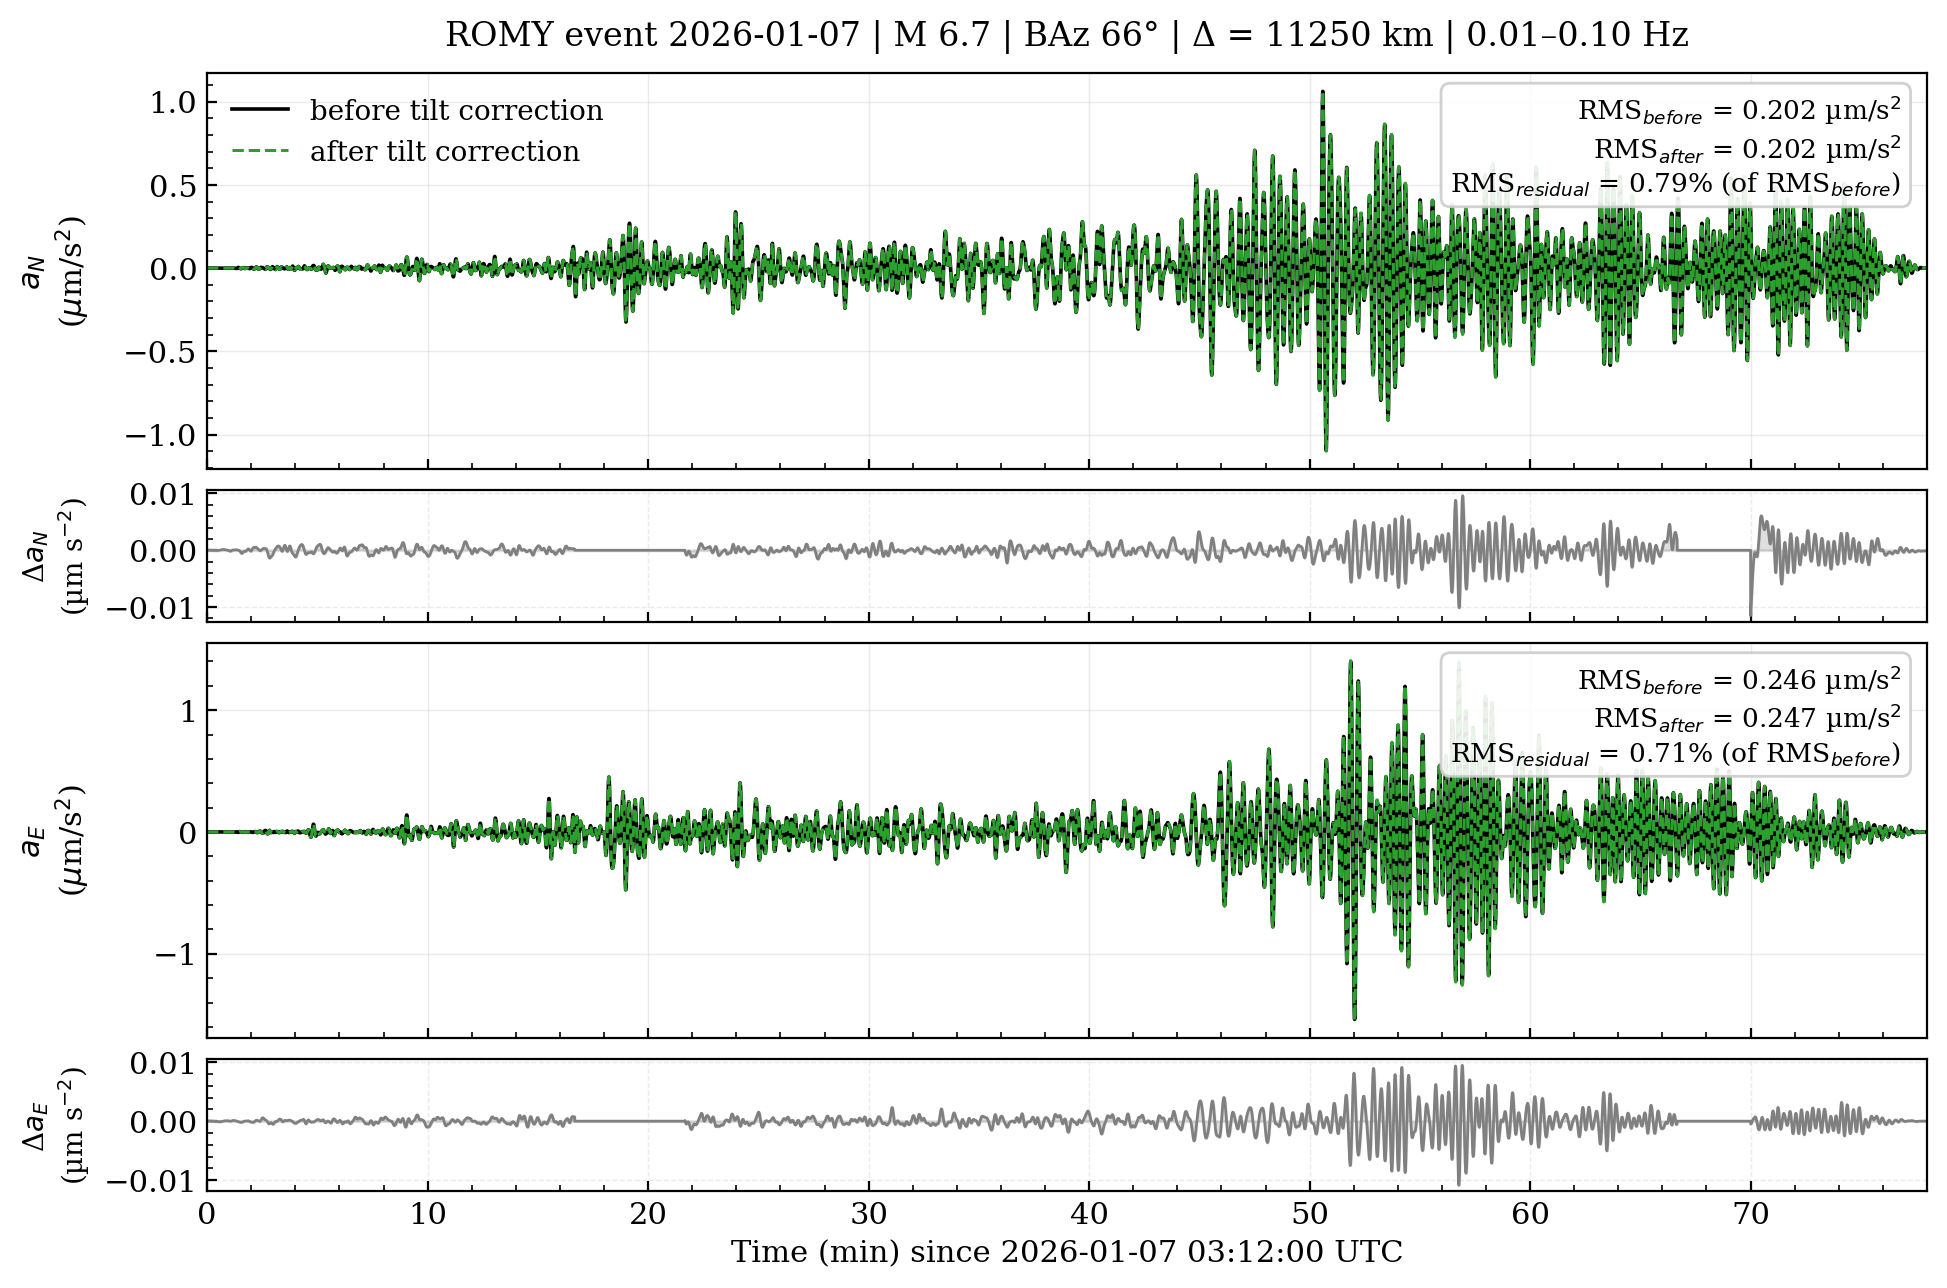

Saved figure to ./output/figures/event_20260107_tilt_correction.png


In [69]:
mag = config.get("magnitude", np.nan)
baz = ev.get("backazimuth", np.nan)
dist = ev.get("distance_km", np.nan)

title_parts = [f"ROMY event {date[:4]}-{date[4:6]}-{date[6:]}", f"M {mag:.1f}"]
if np.isfinite(baz):
    title_parts.append(f"BAz {baz:.0f}°")
if np.isfinite(dist):
    title_parts.append(f"Δ = {dist:.0f} km")
title_parts.append(f"{config['fmin']:.2f}–{config['fmax']:.2f} Hz")
fig_title = " | ".join(title_parts)

fig = plt.figure(figsize=(10, 6.5))
gs = gridspec.GridSpec(4, 1, height_ratios=[3, 1, 3, 1], hspace=0.08)

colors = {
    "before": "black",
    "after": "tab:green",
    "diff": "gray",
}

for i, (ch, label) in enumerate(components):
    tr_b = st_before.select(channel=f"*{ch}")[0]
    tr_a = st_after.select(channel=f"*{ch}")[0]
    t_min = relative_time_minutes(tr_b, ref_time)
    y_b = tr_b.data * scale
    y_a = tr_a.data * scale
    y_d = y_b - y_a
    s = stats[ch]

    ax_main = fig.add_subplot(gs[2 * i])
    ax_diff = fig.add_subplot(gs[2 * i + 1], sharex=ax_main)

    ax_main.plot(t_min, y_b, color=colors["before"], lw=1.3, label="before tilt correction")
    ax_main.plot(t_min, y_a, color=colors["after"], lw=1.1, ls="--", label="after tilt correction")
    ax_main.set_xlim(0, t_min.max())
    ax_main.set_ylabel(f"{label}\n({unit_label})")
    ax_main.grid(True, alpha=0.25, lw=0.5)
    if i == 0:
        ax_main.set_xticklabels([])
    metric_text = (
        f"RMS$_{{before}}$ = {s['rms_before']:.3f} µm/s$^{{2}}$\n"
        f"RMS$_{{after}}$ = {s['rms_after']:.3f} µm/s$^{{2}}$\n"
        f"Var. reduction = {s['var_reduction_pct']:.2f}%"
    )
    ax_main.text(
        0.985, 0.95, metric_text,
        transform=ax_main.transAxes,
        va="top", ha="right",
        fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="0.8", alpha=0.9),
    )

    if i == 0:
        ax_main.legend(loc="upper left", fontsize=10)
        ax_main.set_title(fig_title, fontsize=12, pad=10)
    else:
        plt.setp(ax_main.get_xticklabels(), visible=False)

    ax_diff.plot(t_min, y_d, color=colors["diff"], lw=1.0)
    # ax_diff.axhline(0, color="0.4", lw=0.6)
    ax_diff.fill_between(t_min, 0, y_d, color=colors["diff"], alpha=0.25)
    ax_diff.set_ylabel(f"Δ{label}\n"+r"(µm s$^{-2}$)", fontsize=10)
    ax_diff.grid(True, alpha=0.25, lw=0.5, ls="--")

    if i < len(components) - 1:
        plt.setp(ax_diff.get_xticklabels(), visible=False)

ax_diff.set_xlabel(f"Time (min) since {str(ref_time)[:-8].replace('T', ' ')} UTC")

fig.align_ylabels()
fig.subplots_adjust(left=0.11, right=0.97, top=0.94, bottom=0.08)
plt.show()

if save_figure:
    os.makedirs(output_dir, exist_ok=True)
    out_path = os.path.join(output_dir, f"event_{date}_tilt_correction.png")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"Saved figure to {out_path}")

## Tilt residual vs theoretical backazimuth (all events)

Multi-event view from `output/results_correlation.csv` (run `04_XROMY_event_analysis_cc.py` first). Plots tilt-correction variance reduction (%) for North and East against theoretical backazimuth to check for a systematic dependence.

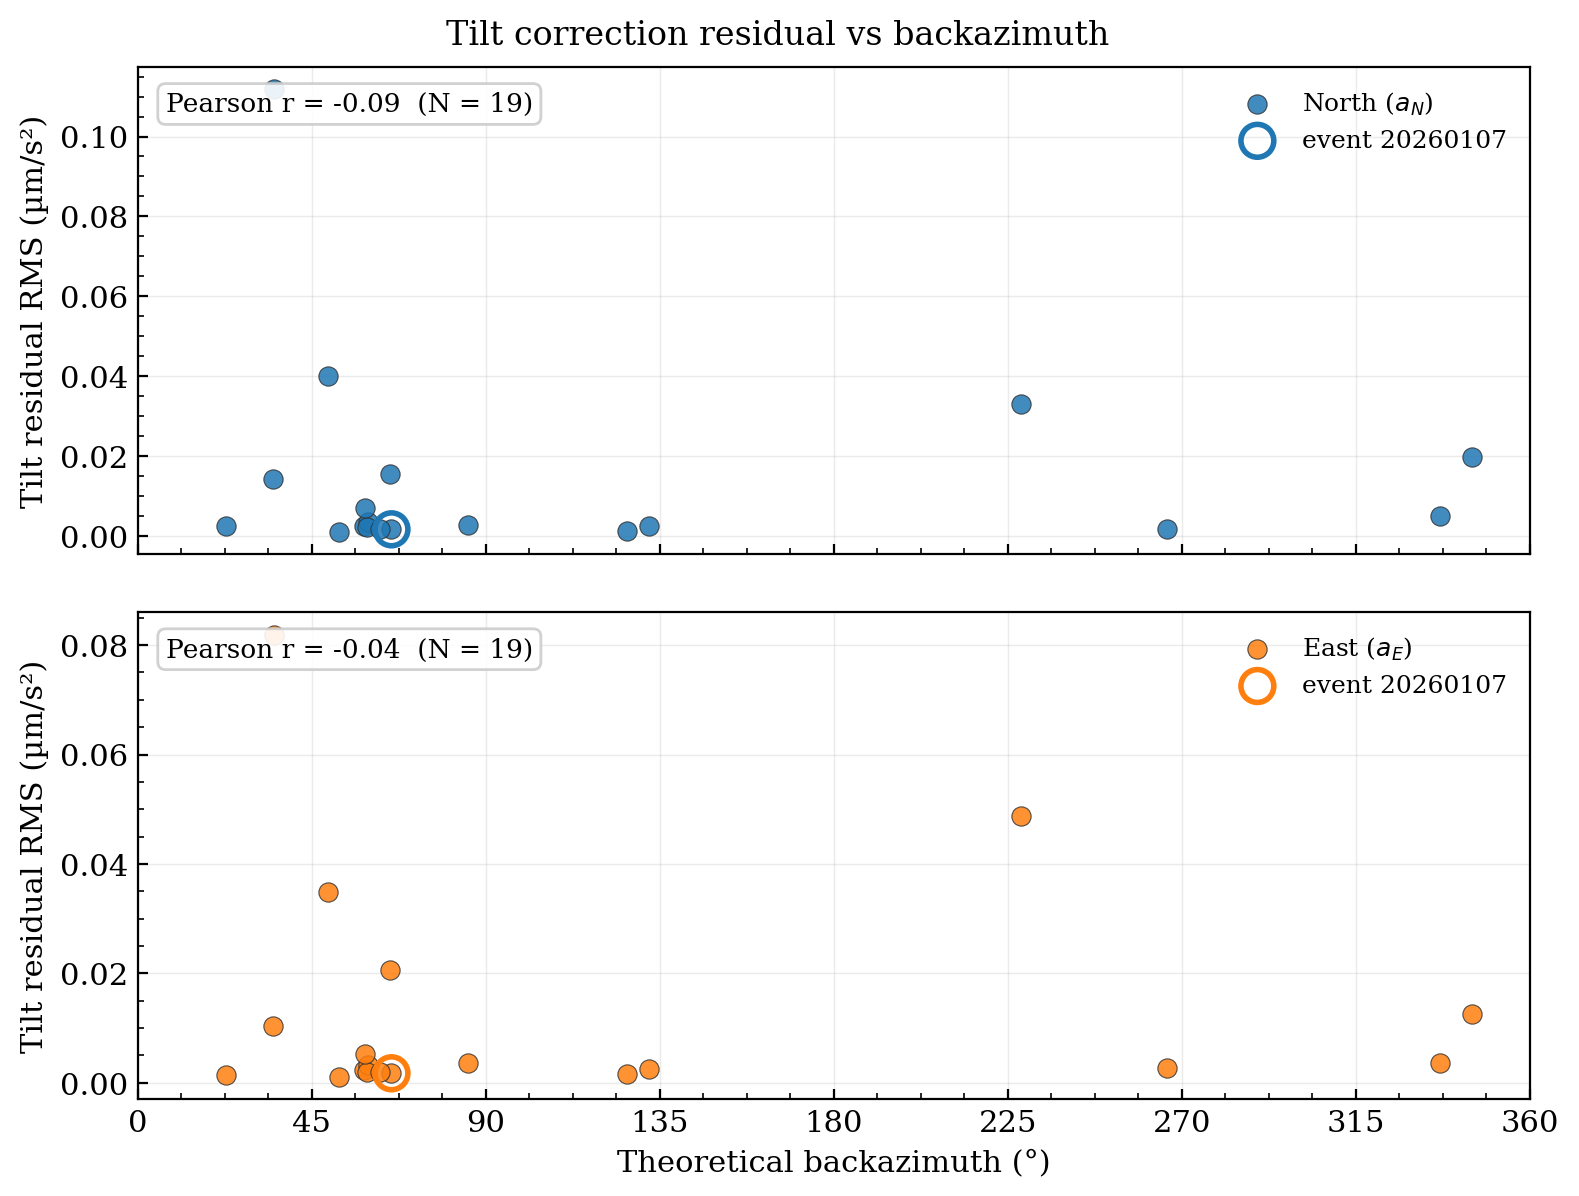

Saved figure to ./output/figures/tilt_residual_vs_backazimuth.png


In [72]:
import pandas as pd

path_to_tilt_csv = "./output/results_correlation.csv"
if not os.path.exists(path_to_tilt_csv):
    raise FileNotFoundError(
        f"Missing {path_to_tilt_csv}. Run: python 04_XROMY_event_analysis_cc.py --events-file events_list.yml"
    )

df = pd.read_csv(path_to_tilt_csv)
df_tilt = (
    df.sort_values("wave_type")
    .drop_duplicates("event_date", keep="first")
    .dropna(subset=["backazimuth_theoretical", "var_reduction_north", "var_reduction_east"])
    .copy()
)
df_tilt["event_date"] = df_tilt["event_date"].astype(str)

def _pearson_r(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if len(x) < 2:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, height_ratios=[1, 1])
plot_specs = (
    ("var_reduction_north", r"North ($a_N$)", "tab:blue"),
    ("var_reduction_east", r"East ($a_E$)", "tab:orange"),
)

for ax, (col, label, color) in zip(axes, plot_specs):
    baz = df_tilt["backazimuth_theoretical"].values
    rms = df_tilt[col].values
    ax.scatter(
        baz, rms, s=48, c=color, alpha=0.85,
        edgecolors="0.2", linewidths=0.4, label=label, zorder=2,
    )

    # Highlight the single-event analysed above
    if str(date) in df_tilt["event_date"].values:
        row = df_tilt.loc[df_tilt["event_date"] == str(date)].iloc[0]
        ax.scatter(
            row["backazimuth_theoretical"], row[col],
            s=140, facecolors="none", edgecolors=color, linewidths=2.0, zorder=3,
            label=f"event {date}",
        )

    r_val = _pearson_r(baz, rms)
    ax.text(
        0.02, 0.95, f"Pearson r = {r_val:.2f}  (N = {len(df_tilt)})",
        transform=ax.transAxes, va="top", ha="left", fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="0.8", alpha=0.9),
    )
    ax.set_ylabel("Variance reduction (%)")
    ax.set_xlim(0, 360)
    ax.set_xticks(np.arange(0, 361, 45))
    ax.grid(True, alpha=0.25, lw=0.5)
    ax.legend(loc="upper right", fontsize=9)

axes[-1].set_xlabel("Theoretical backazimuth (°)")
fig.suptitle("Tilt correction variance reduction vs backazimuth", fontsize=12, y=0.98)
fig.subplots_adjust(hspace=0.12, top=0.94, bottom=0.08, left=0.10, right=0.97)
plt.show()

if save_figure:
    os.makedirs(output_dir, exist_ok=True)
    out_path = os.path.join(output_dir, "tilt_var_reduction_vs_backazimuth.png")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"Saved figure to {out_path}")